#  La Poule qui Chante - Étude de marché internationale
## Notebook 1 - Préparation, nettoyage et exploration des données

**Contexte :** La Poule qui Chante, entreprise française d'élevage de poulet bio, souhaite s'internationaliser.
Patrick (PDG) demande une analyse des groupements de pays pour identifier où exporter.

**Plan de ce notebook :**
1. Chargement et exploration de la table FAO brute
2. Pivot et agrégation de la table FAO
3. Sélection des variables pertinentes
4. Feature engineering (création de ratios)
5. Jointure avec les données externes (Banque mondiale, FAO Population)
6. Nettoyage final
7. Exploration des données

**Cadre PESTEL utilisé pour guider le choix des variables :**
Politique · Économique · Socioculturel · Technologique · Environnemental · Légal

## 1. Imports et configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_palette('Blues_r')

print(' Imports OK')

 Imports OK


## 2. Chargement et exploration de la table FAO brute

La table FAO `DisponibiliteAlimentaire_2017.csv` est au **format long** :
chaque ligne = un pays × un produit × un élément.

Avant tout filtrage, on explore la structure complète pour comprendre ce qui est disponible.

In [2]:
# Chargement avec encoding latin-1
fao_raw = pd.read_csv('DisponibiliteAlimentaire_2017.csv', encoding='latin1')
fao_raw.columns = ['Code_Domaine','Domaine','Code_Zone','Zone','Code_Element',
                   'Element','Code_Produit','Produit','Code_Annee','Annee',
                   'Unite','Valeur','Symbole','Description']

# Corriger l'encodage
for col in ['Zone','Element','Produit','Description']:
    fao_raw[col] = fao_raw[col].apply(
        lambda x: x.encode('latin1').decode('utf-8') if isinstance(x, str) else x
    )

fao_raw

,Code_Domaine,Domaine,Code_Zone,Zone,Code_Element,Element,Code_Produit,Produit,Code_Annee,Annee,Unite,Valeur,Symbole,Description
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.00,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.00,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.00,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.00,S,Données standardisées
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176595,FBS,Nouveaux Bilans Alimentaire,181,Zimbabwe,5142,Nourriture,2899,Miscellanees,2017,2017,Milliers de tonnes,19.00,S,Données standardisées
176596,FBS,Nouveaux Bilans Alimentaire,181,Zimbabwe,645,Disponibilité alimentaire en quantité (kg/pers...,2899,Miscellanees,2017,2017,kg,1.33,Fc,Donnée calculée
176597,FBS,Nouveaux Bilans Alimentaire,181,Zimbabwe,664,Disponibilité alimentaire (Kcal/personne/jour),2899,Miscellanees,2017,2017,Kcal/personne/jour,1.00,Fc,Donnée calculée
176598,FBS,Nouveaux Bilans Alimentaire,181,Zimbabwe,674,Disponibilité de protéines en quantité (g/pers...,2899,Miscellanees,2017,2017,g/personne/jour,0.04,Fc,Donnée calculée


In [3]:
# Explorer les éléments disponibles
print('=== ÉLÉMENTS DISPONIBLES ===')
for e in sorted(fao_raw['Element'].unique()):
    print(f'  - {e}')

fao_raw['Produit'].unique()


=== ÉLÉMENTS DISPONIBLES ===
  - Alimentation pour touristes
  - Aliments pour animaux
  - Autres utilisations (non alimentaire)
  - Disponibilité alimentaire (Kcal/personne/jour)
  - Disponibilité alimentaire en quantité (kg/personne/an)
  - Disponibilité de matière grasse en quantité (g/personne/jour)
  - Disponibilité de protéines en quantité (g/personne/jour)
  - Disponibilité intérieure
  - Exportations - Quantité
  - Importations - Quantité
  - Nourriture
  - Pertes
  - Production
  - Résidus
  - Semences
  - Traitement
  - Variation de stock


array(['Blé et produits', 'Riz et produits', 'Orge et produits',
       'Maïs et produits', 'Seigle et produits', 'Avoine',
       'Millet et produits', 'Sorgho et produits', 'Céréales, Autres',
       'Pommes de Terre et produits', 'Ignames', 'Racines nda',
       'Sucre, canne', 'Sucre, betterave', 'Sucre Eq Brut',
       'Edulcorants Autres', 'Miel', 'Haricots', 'Pois',
       'Légumineuses Autres et produits', 'Noix et produits', 'Soja',
       'Arachides Decortiquees', 'Graines de tournesol',
       'Graines Colza/Moutarde', 'Graines de coton', 'Coco (Incl Coprah)',
       'Sésame', 'Olives', 'Plantes Oleiferes, Autre', 'Huile de Soja',
       "Huile d'Arachide", 'Huile de Tournesol',
       'Huile de Colza&Moutarde', 'Huile Graines de Coton',
       'Huile de Palmistes', 'Huile de Palme', 'Huile de Coco',
       'Huile de Sésame', "Huile d'Olive", 'Huile de Son de Riz',
       'Huile de Germe de Maïs', 'Huil Plantes Oleif Autr',
       'Tomates et produits', 'Oignons', 'Légumes, 

## 3. Pivot et agrégation de la table FAO

On passe du **format long** (1 ligne = 1 mesure) au **format large** (1 ligne = 1 pays) via un pivot.

Trois niveaux d'agrégation sont construits :

| Préfixe | Contenu | Utilité |
|---|---|---|
| `Total_` | Tous produits alimentaires confondus | Vue macro de l'alimentation |
| `Viandes_` | Toutes viandes (bovins, porc, ovins, volaille, autres) | Contexte marché viandes |
| `Volaille_` | Viande de volailles uniquement | **Variable cible** |

**Résultat attendu :** 174 pays × 42 variables


In [4]:
# Produits et éléments à extraire
PRODUITS = {
    'Viande de Volailles'    : 'Volaille',
    'Viande de Bovins'       : 'Bovins',
    'Viande de Suides'       : 'Porc',
    "Viande d'Ovins/Caprins" : 'Ovins',
    'Viande, Autre'          : 'AutresViandes',
    'Oeufs'                  : 'Oeufs',
}

ELEMENTS = {
    'Production'                                              : 'Production',
    'Importations - Quantité'                                 : 'Importations',
    'Exportations - Quantité'                                 : 'Exportations',
    'Disponibilité intérieure'                                : 'DispoInterieure',
    'Nourriture'                                              : 'Nourriture',
    'Disponibilité alimentaire en quantité (kg/personne/an)'  : 'kg_hab',
    'Disponibilité alimentaire (Kcal/personne/jour)'          : 'Kcal_hab',
    'Disponibilité de protéines en quantité (g/personne/jour)': 'Proteines_hab',
}

# Filtrage
fao_filtre = fao_raw[
    (fao_raw['Produit'].isin(PRODUITS.keys())) &
    (fao_raw['Element'].isin(ELEMENTS.keys()))
].copy()

# Renommer
fao_filtre['Produit_court'] = fao_filtre['Produit'].map(PRODUITS)
fao_filtre['Element_court'] = fao_filtre['Element'].map(ELEMENTS)

# Créer le nom de colonne : Produit_Element
fao_filtre['Variable'] = fao_filtre['Produit_court'] + '_' + fao_filtre['Element_court']

print(f'Lignes après filtrage : {len(fao_filtre)}')
print(f'Variables créées : {fao_filtre["Variable"].nunique()}')
print(fao_filtre['Variable'].unique()[:10])

Lignes après filtrage : 7806
Variables créées : 48
['Bovins_Production' 'Bovins_Importations' 'Bovins_DispoInterieure'
 'Bovins_Nourriture' 'Bovins_kg_hab' 'Bovins_Kcal_hab'
 'Bovins_Proteines_hab' 'Ovins_Production' 'Ovins_Importations'
 'Ovins_DispoInterieure']


In [5]:
import pandas as pd

# ====================== CHARGEMENT DES DONNÉES ======================
fao_raw = pd.read_csv('DisponibiliteAlimentaire_2017.csv')

# ====================== DÉFINITION DES CATÉGORIES DE PRODUITS ======================
poultry = ['Viande de Volailles']

meats = [
    'Viande de Volailles',
    'Viande de Bovins',
    'Viande de Suides',
    "Viande d'Ovins/Caprins",
    'Viande, Autre'
]

# ====================== FILTRE SUR LES ÉLÉMENTS À AGRÉGER ======================
elements_to_keep = fao_raw["Élément"].unique()


# Filtre du dataframe brut
df_qty = fao_raw[
    (fao_raw['Unité'] == 'Milliers de tonnes') &
    (fao_raw['Élément'].isin(elements_to_keep))
].copy()

# ====================== CRÉATION DE LA COLONNE CATÉGORIE ======================
def get_category(produit):
    if produit in poultry:
        return 'Volaille'
    elif produit in meats:
        return 'Viandes'
    else:
        return 'Total'

df_qty['Category'] = df_qty['Produit'].apply(get_category)

# ====================== AGRÉGATION PAR CATÉGORIE ======================
# 1. Volaille seulement
volaille_agg = df_qty[df_qty['Category'] == 'Volaille'].groupby(['Zone', 'Élément'])['Valeur'].sum().reset_index()
volaille_agg['Category'] = 'Volaille'

# 2. Ensemble des viandes
viandes_agg = df_qty[df_qty['Category'].isin(['Volaille', 'Viandes'])].groupby(['Zone', 'Élément'])['Valeur'].sum().reset_index()
viandes_agg['Category'] = 'Viandes'

# 3. Total de tous les produits
total_agg = df_qty.groupby(['Zone', 'Élément'])['Valeur'].sum().reset_index()
total_agg['Category'] = 'Total'

# Union
agg_all = pd.concat([volaille_agg, viandes_agg, total_agg], ignore_index=True)

# ====================== PIVOT FINAL ======================
pivot = agg_all.pivot_table(
    index='Zone',
    columns=['Category', 'Élément'],
    values='Valeur',
    aggfunc='first'
).round(2)

pivot.columns = [f"{cat}_{elem}" for cat, elem in pivot.columns]
pivot = pivot.reset_index()

# ====================== INDICATEURS PAR HABITANT (volaille uniquement) ======================
per_capita = fao_raw[
    (fao_raw['Produit'] == 'Viande de Volailles') &
    (fao_raw['Élément'].str.contains('Disponibilité alimentaire', na=False))
].pivot_table(
    index='Zone',
    columns='Élément',
    values='Valeur'
).round(2)

per_capita.columns = [f"Volaille_{col}" for col in per_capita.columns]
per_capita = per_capita.reset_index()

# ====================== FUSION FINALE ======================
final_df = pivot.merge(per_capita, on='Zone', how='left')

# ====================== EXPORT ======================
display(final_df.head())
print(f"\nShape du tableau final : {final_df.shape} lignes (pays)")
final_df.columns

,Zone,Total_Alimentation pour touristes,Total_Aliments pour animaux,Total_Autres utilisations (non alimentaire),Total_Disponibilité intérieure,Total_Exportations - Quantité,Total_Importations - Quantité,Total_Nourriture,Total_Pertes,Total_Production,...,Volaille_Importations - Quantité,Volaille_Nourriture,Volaille_Pertes,Volaille_Production,Volaille_Résidus,Volaille_Semences,Volaille_Traitement,Volaille_Variation de stock,Volaille_Disponibilité alimentaire (Kcal/personne/jour),Volaille_Disponibilité alimentaire en quantité (kg/personne/an)
0,Afghanistan,NaN,456.0,94.0,15139.0,601.0,4555.0,12968.0,1146.0,11609.0,...,29.0,55.0,2.0,28.0,0.0,NaN,NaN,0.0,5.0,1.53
1,Afrique du Sud,0.0,9371.0,1448.0,66840.0,10968.0,9020.0,31726.0,3108.0,68455.0,...,514.0,2035.0,83.0,1667.0,0.0,NaN,NaN,0.0,143.0,35.69
2,Albanie,NaN,697.0,177.0,4879.0,156.0,884.0,3631.0,321.0,4231.0,...,38.0,47.0,NaN,13.0,0.0,NaN,NaN,4.0,85.0,16.36
3,Algérie,0.0,4884.0,2405.0,45365.0,743.0,19718.0,33056.0,3683.0,26763.0,...,2.0,264.0,13.0,275.0,0.0,NaN,NaN,0.0,22.0,6.38
4,Allemagne,NaN,30904.0,8316.0,174960.0,58793.0,66550.0,77988.0,5756.0,167828.0,...,842.0,1609.0,NaN,1514.0,-38.0,NaN,167.0,-29.0,71.0,19.47



Shape du tableau final : (174, 42) lignes (pays)


Index(['Zone', 'Total_Alimentation pour touristes',
       'Total_Aliments pour animaux',
       'Total_Autres utilisations (non alimentaire)',
       'Total_Disponibilité intérieure', 'Total_Exportations - Quantité',
       'Total_Importations - Quantité', 'Total_Nourriture', 'Total_Pertes',
       'Total_Production', 'Total_Résidus', 'Total_Semences',
       'Total_Traitement', 'Total_Variation de stock',
       'Viandes_Alimentation pour touristes', 'Viandes_Aliments pour animaux',
       'Viandes_Autres utilisations (non alimentaire)',
       'Viandes_Disponibilité intérieure', 'Viandes_Exportations - Quantité',
       'Viandes_Importations - Quantité', 'Viandes_Nourriture',
       'Viandes_Pertes', 'Viandes_Production', 'Viandes_Résidus',
       'Viandes_Semences', 'Viandes_Traitement', 'Viandes_Variation de stock',
       'Volaille_Alimentation pour touristes',
       'Volaille_Aliments pour animaux',
       'Volaille_Autres utilisations (non alimentaire)',
       'Volaille_Dispo

## 4. Sélection des variables et feature engineering

### 4.1 Sélection des 10 variables retenues

À partir des 42 variables disponibles, on retient les **10 variables les plus pertinentes** pour l'analyse de marché export de poulet bio.

**Justification PESTEL :**

| Variable | Catégorie PESTEL | Interprétation |
|---|---|---|
| `Volaille_Per_Capita_kg` | Social | Demande existante par habitant |
| `Volaille_Import_Dependency` | Économique | Part des imports dans la consommation |
| `Volaille_Self_Sufficiency` | Économique | Capacité de production locale |
| `Volaille_Net_Import` | Économique | Solde importateur/exportateur |
| `Volaille_Production_Gap` | Économique | Besoin non couvert localement |
| `Poultry_Share_in_Meat_Consumption` | Social | Orientation culturelle vers la volaille |
| `Viandes_Import_Dependency` | Économique | Dépendance globale aux imports de viandes |
| `Volaille_Import_Cover_Ratio` | Économique | Rôle des imports pour combler le gap |
| `Total_Meat_Consumption` | Social | Taille absolue du marché viande |

> Les variables avec un fort ratio d'importation et une faible autosuffisance représentent les **meilleures opportunités d'export**.


In [6]:
import pandas as pd
import numpy as np

# ====================== PARTIR DIRECTEMENT DE final_df ======================
# (assure-toi que final_df existe déjà avec les colonnes Volaille_*, Viandes_*, Total_*)

df = final_df.copy()

# ====================== CRÉATION DES NOUVELLES VARIABLES DÉRIVÉES ======================
# Ratios et indicateurs clés pour l'export de poulet
df['Volaille_Self_Sufficiency']      = df['Volaille_Production'] / df['Volaille_Nourriture'].replace(0, np.nan)
df['Volaille_Import_Dependency']     = df['Volaille_Importations - Quantité'] / df['Volaille_Nourriture'].replace(0, np.nan)
df['Viandes_Import_Dependency']      = df['Volaille_Importations - Quantité'] / df['Viandes_Nourriture'].replace(0, np.nan)

df['Volaille_Net_Import']            = df['Volaille_Importations - Quantité'] - df['Volaille_Exportations - Quantité']
df['Volaille_Production_Gap']        = df['Volaille_Nourriture'] - df['Volaille_Production']

df['Poultry_Share_in_Meat_Consumption'] = df['Volaille_Nourriture'] / df['Viandes_Nourriture'].replace(0, np.nan)
df['Volaille_Import_Cover_Ratio']    = df['Volaille_Importations - Quantité'] / df['Volaille_Production_Gap'].clip(lower=0.1)

df['Volaille_Import_vs_Production']  = df['Volaille_Importations - Quantité'] / df['Volaille_Production'].replace(0, np.nan)
df['Total_Meat_Consumption']         = df['Viandes_Nourriture']

# Indicateur par habitant (déjà présent, on le garde tel quel)
if 'Volaille_Disponibilité alimentaire en quantité (kg/personne/an)' in df.columns:
    df['Volaille_Per_Capita_kg'] = df['Volaille_Disponibilité alimentaire en quantité (kg/personne/an)']

# ====================== SÉLECTION DES TOP 10 VARIABLES LES PLUS UTILES ======================
top_10_vars = [
    'Zone',
    'Volaille_Per_Capita_kg',                    # Taille du marché par habitant
    'Volaille_Import_Dependency',                # Dépendance aux importations de poulet
    'Volaille_Self_Sufficiency',                 # Autosuffisance en poulet
    'Volaille_Net_Import',                       # Solde net importateur
    'Volaille_Production_Gap',                   # Besoin non couvert localement
    'Poultry_Share_in_Meat_Consumption',         # Part du poulet dans la viande consommée
    'Viandes_Import_Dependency',                 # Dépendance globale aux importations de viande
    'Volaille_Import_Cover_Ratio',               # Importance des importations pour combler le gap
    'Total_Meat_Consumption'                     # Taille absolue du marché viande
]

final_top10 = df[top_10_vars].copy()

# Nettoyage léger
final_top10 = final_top10.replace([np.inf, -np.inf], np.nan).round(4)

display(final_top10.head())
print(f"\nShape final : {final_top10.shape} (1 ligne par pays)")

final_df = final_top10.copy()
print(f'final_df mis a jour : {final_df.shape}')


,Zone,Volaille_Per_Capita_kg,Volaille_Import_Dependency,Volaille_Self_Sufficiency,Volaille_Net_Import,Volaille_Production_Gap,Poultry_Share_in_Meat_Consumption,Viandes_Import_Dependency,Volaille_Import_Cover_Ratio,Total_Meat_Consumption
0,Afghanistan,1.53,0.5273,0.5091,NaN,27.0,0.1763,0.0929,1.0741,312.0
1,Afrique du Sud,35.69,0.2526,0.8192,451.0,368.0,0.5947,0.1502,1.3967,3422.0
2,Albanie,16.36,0.8085,0.2766,38.0,34.0,0.3456,0.2794,1.1176,136.0
3,Algérie,6.38,0.0076,1.0417,2.0,-11.0,0.3529,0.0027,20.0000,748.0
4,Allemagne,19.47,0.5233,0.9410,196.0,95.0,0.2218,0.1161,8.8632,7255.0



Shape final : (174, 10) (1 ligne par pays)
final_df mis a jour : (174, 10)


### 4.2 Feature engineering

> ⚠️ Le feature engineering a été réalisé directement lors du pivot (cellule précédente). Les variables dérivées sont déjà incluses dans `final_df`.

Les principales variables dérivées créées :
- **Ratios de dépendance** : importations / disponibilité intérieure
- **Ratios d'autosuffisance** : production / disponibilité intérieure  
- **Soldes commerciaux** : importations - exportations
- **Parts de marché** : volaille / total viandes


## 5. Jointure avec les données externes (PESTEL)

On enrichit le dataset FAO avec des indicateurs **Banque mondiale** pour couvrir toutes les dimensions PESTEL.

| Indicateur | Code WB | PESTEL | Intérêt |
|---|---|---|---|
| PIB par habitant | NY.GDP.PCAP.CD | Économique | Pouvoir d'achat pour produits bio premium |
| Croissance du PIB | NY.GDP.MKTP.KD.ZG | Économique | Dynamisme du marché |
| Taux d'urbanisation | SP.URB.TOTL.IN.ZS | Social | Concentration de consommateurs urbains |
| Accès internet | IT.NET.USER.ZS | Technologique | Proxy de développement économique |
| Surface agricole | AG.LND.AGRI.ZS | Environnemental | Contexte agricole local |
| Population totale | FAO Pop. 2017 | Social | Taille absolue du marché |

**Méthode :** jointure LEFT sur le nom du pays - tous les pays FAO sont conservés, les données WB manquantes sont imputées par la médiane.


In [7]:
import os, zipfile, glob

def charger_wb_zip(dossier, code_indicateur, nom_variable, annee=2017):
    pattern = os.path.join(dossier, f'*{code_indicateur}*.zip')
    zips = glob.glob(pattern)
    if not zips:
        print(f'ZIP introuvable pour {code_indicateur}')
        return None

    with zipfile.ZipFile(zips[0], 'r') as z:
        csv_names = [n for n in z.namelist() if n.startswith('API_') and n.endswith('.csv')]
        if not csv_names:
            return None
        with z.open(csv_names[0]) as f:
            df_tmp = pd.read_csv(f, skiprows=4, encoding='latin1')

    annee_str = str(annee)
    if annee_str not in df_tmp.columns:
        annees = [c for c in df_tmp.columns if str(c).isdigit()]
        annee_str = str(min(annees, key=lambda x: abs(int(x) - annee)))

    resultat = df_tmp[['Country Name', 'Country Code', annee_str]].copy()
    resultat.columns = ['Pays_WB', 'Code_ISO3', nom_variable]
    resultat = resultat.dropna(subset=[nom_variable])
    resultat = resultat[resultat['Code_ISO3'].notna() & (resultat['Code_ISO3'] != '')]
    print(f'  {nom_variable} : {len(resultat)} pays')
    return resultat


DOSSIER = '.'   # meme dossier que le notebook

indicateurs = {
    'NY.GDP.PCAP.CD'    : 'PIB_par_habitant',
    'NY.GDP.MKTP.KD.ZG' : 'Croissance_PIB',
    'SP.URB.TOTL.IN.ZS' : 'Taux_Urbanisation',
    'IT.NET.USER.ZS'    : 'Acces_Internet',
    'AG.LND.AGRI.ZS'    : 'Surface_Agricole',
}

df_wb = None
print('Chargement donnees Banque mondiale...')
for code, nom in indicateurs.items():
    tmp = charger_wb_zip(DOSSIER, code, nom)
    if tmp is not None:
        if df_wb is None:
            df_wb = tmp
        else:
            df_wb = df_wb.merge(tmp[['Code_ISO3', nom]], on='Code_ISO3', how='outer')

print(f'\nDimensions WB : {df_wb.shape}')
df_wb.head(3)

Chargement donnees Banque mondiale...
  PIB_par_habitant : 259 pays
  Croissance_PIB : 258 pays
  Taux_Urbanisation : 265 pays
  Acces_Internet : 233 pays
  Surface_Agricole : 258 pays

Dimensions WB : (265, 7)


,Pays_WB,Code_ISO3,PIB_par_habitant,Croissance_PIB,Taux_Urbanisation,Acces_Internet,Surface_Agricole
0,Aruba,ABW,28440.041688,3.493430,62.776849,97.17,11.111111
1,Africa Eastern and Southern,AFE,1528.104224,2.677524,35.282987,17.30,46.246059
2,Afghanistan,AFG,525.469771,2.647003,24.835282,13.50,58.123668


In [17]:
import csv

# Première lecture - chaque ligne de données = 1 seul élément entre guillemets
lignes_raw = []
with open('Population_2000_2018.csv', 'r', encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f)
    for ligne in reader:
        lignes_raw.append(ligne)

# Deuxième passe - si 1 seul élément, on le re-parse comme CSV
lignes = []
for row in lignes_raw:
    if len(row) == 1 and row[0]:
        inner = list(csv.reader([row[0]]))[0]
        lignes.append(inner)
    else:
        lignes.append(row)

print(f'Lignes : {len(lignes)}')
print(f'Colonnes ligne 0 : {len(lignes[0])}')
print(f'Colonnes ligne 1 : {len(lignes[1])}')
print(f'Aperçu ligne 1 : {lignes[1][:4]}')

# Construire le DataFrame
pop_fao = pd.DataFrame(lignes[1:], columns=[
    'Code_Domaine','Domaine','Code_Zone','Zone','Code_Element',
    'Element','Code_Produit','Produit','Code_Annee','Annee',
    'Unite','Valeur','Symbole','Description','Note'
])

pop_fao['Annee'] = pd.to_numeric(pop_fao['Annee'], errors='coerce')
pop_fao['Valeur'] = pd.to_numeric(pop_fao['Valeur'], errors='coerce')

pop_2017 = pop_fao[
    (pop_fao['Annee'] == 2017) &
    (pop_fao['Element'] == 'Population totale')
][['Zone','Valeur']].drop_duplicates('Zone')

pop_2017 = pop_2017.rename(columns={'Zone':'Pays','Valeur':'Population_Totale'})
pop_2017['Population_Totale'] = (pop_2017['Population_Totale'] / 1000).round(2)

print(f'\nPopulation 2017 : {len(pop_2017)} pays')
pop_2017.head(3)

Lignes : 4412
Colonnes ligne 0 : 15
Colonnes ligne 1 : 15
Aperçu ligne 1 : ['OA', 'Séries temporelles annuelles', '2', 'Afghanistan']

Population 2017 : 236 pays


,Pays,Population_Totale
17,Afghanistan,36.30
36,Afrique du Sud,57.01
55,Albanie,2.88


In [9]:
# Correspondance complète : Zone FAO (français) → Code ISO3
fao_vers_iso3 = {
    'Afghanistan'                            : 'AFG',
    'Afrique du Sud'                         : 'ZAF',
    'Albanie'                                : 'ALB',
    'Algérie'                                : 'DZA',
    'Allemagne'                              : 'DEU',
    'Angola'                                 : 'AGO',
    'Antigua-et-Barbuda'                     : 'ATG',
    'Arabie saoudite'                        : 'SAU',
    'Argentine'                              : 'ARG',
    'Arménie'                                : 'ARM',
    'Australie'                              : 'AUS',
    'Autriche'                               : 'AUT',
    'Azerbaïdjan'                            : 'AZE',
    'Bahamas'                                : 'BHS',
    'Bangladesh'                             : 'BGD',
    'Barbade'                                : 'BRB',
    'Bélarus'                                : 'BLR',
    'Belgique'                               : 'BEL',
    'Belize'                                 : 'BLZ',
    'Bénin'                                  : 'BEN',
    'Bhoutan'                                : 'BTN',
    'Bolivie'                                : 'BOL',
    'Bosnie-Herzégovine'                     : 'BIH',
    'Botswana'                               : 'BWA',
    'Brésil'                                 : 'BRA',
    'Brunéi Darussalam'                      : 'BRN',
    'Bulgarie'                               : 'BGR',
    'Burkina Faso'                           : 'BFA',
    'Burundi'                                : 'BDI',
    'Cabo Verde'                             : 'CPV',
    'Cambodge'                               : 'KHM',
    'Cameroun'                               : 'CMR',
    'Canada'                                 : 'CAN',
    'Chili'                                  : 'CHL',
    'Chine'                                  : 'CHN',
    'Chypre'                                 : 'CYP',
    'Colombie'                               : 'COL',
    'Comores'                                : 'COM',
    'Congo'                                  : 'COG',
    'Corée du Nord'                          : 'PRK',
    'Corée du Sud'                           : 'KOR',
    "Côte d'Ivoire"                          : 'CIV',
    'Costa Rica'                             : 'CRI',
    'Croatie'                                : 'HRV',
    'Cuba'                                   : 'CUB',
    'Danemark'                               : 'DNK',
    'Djibouti'                               : 'DJI',
    'Dominique'                              : 'DMA',
    'Égypte'                                 : 'EGY',
    'El Salvador'                            : 'SLV',
    'Émirats arabes unis'                    : 'ARE',
    'Équateur'                               : 'ECU',
    'Érythrée'                               : 'ERI',
    'Espagne'                                : 'ESP',
    'Estonie'                                : 'EST',
    'Eswatini'                               : 'SWZ',
    "États-Unis d'Amérique"                  : 'USA',
    'Éthiopie'                               : 'ETH',
    'Fidji'                                  : 'FJI',
    'Finlande'                               : 'FIN',
    'France'                                 : 'FRA',
    'Gabon'                                  : 'GAB',
    'Gambie'                                 : 'GMB',
    'Géorgie'                                : 'GEO',
    'Ghana'                                  : 'GHA',
    'Grèce'                                  : 'GRC',
    'Guatemala'                              : 'GTM',
    'Guinée'                                 : 'GIN',
    'Guinée-Bissau'                          : 'GNB',
    'Guinée équatoriale'                     : 'GNQ',
    'Guyana'                                 : 'GUY',
    'Haïti'                                  : 'HTI',
    'Honduras'                               : 'HND',
    'Hongrie'                                : 'HUN',
    'Inde'                                   : 'IND',
    'Indonésie'                              : 'IDN',
    'Irak'                                   : 'IRQ',
    'Iran'                                   : 'IRN',
    'Irlande'                                : 'IRL',
    'Islande'                                : 'ISL',
    'Israël'                                 : 'ISR',
    'Italie'                                 : 'ITA',
    'Jamaïque'                               : 'JAM',
    'Japon'                                  : 'JPN',
    'Jordanie'                               : 'JOR',
    'Kazakhstan'                             : 'KAZ',
    'Kenya'                                  : 'KEN',
    'Kirghizistan'                           : 'KGZ',
    'Koweït'                                 : 'KWT',
    'Laos'                                   : 'LAO',
    'Lesotho'                                : 'LSO',
    'Lettonie'                               : 'LVA',
    'Liban'                                  : 'LBN',
    'Libéria'                                : 'LBR',
    'Libye'                                  : 'LBY',
    'Lituanie'                               : 'LTU',
    'Luxembourg'                             : 'LUX',
    'Macédoine du Nord'                      : 'MKD',
    'Madagascar'                             : 'MDG',
    'Malaisie'                               : 'MYS',
    'Malawi'                                 : 'MWI',
    'Maldives'                               : 'MDV',
    'Mali'                                   : 'MLI',
    'Malte'                                  : 'MLT',
    'Maroc'                                  : 'MAR',
    'Maurice'                                : 'MUS',
    'Mauritanie'                             : 'MRT',
    'Mexique'                                : 'MEX',
    'Moldavie'                               : 'MDA',
    'Mongolie'                               : 'MNG',
    'Mozambique'                             : 'MOZ',
    'Myanmar'                                : 'MMR',
    'Namibie'                                : 'NAM',
    'Népal'                                  : 'NPL',
    'Nicaragua'                              : 'NIC',
    'Niger'                                  : 'NER',
    'Nigéria'                                : 'NGA',
    'Norvège'                                : 'NOR',
    'Nouvelle-Zélande'                       : 'NZL',
    'Ouganda'                                : 'UGA',
    'Ouzbékistan'                            : 'UZB',
    'Pakistan'                               : 'PAK',
    'Panama'                                 : 'PAN',
    'Papouasie-Nouvelle-Guinée'              : 'PNG',
    'Paraguay'                               : 'PRY',
    'Pays-Bas (Royaume des)'                 : 'NLD',
    'Pérou'                                  : 'PER',
    'Philippines'                            : 'PHL',
    'Pologne'                                : 'POL',
    'Portugal'                               : 'PRT',
    'République centrafricaine'              : 'CAF',
    'République démocratique du Congo'       : 'COD',
    'République dominicaine'                 : 'DOM',
    'République tchèque'                     : 'CZE',
    'Roumanie'                               : 'ROU',
    'Royaume-Uni de Grande-Bretagne'         : 'GBR',
    'Russie'                                 : 'RUS',
    'Rwanda'                                 : 'RWA',
    'Sénégal'                                : 'SEN',
    'Serbie'                                 : 'SRB',
    'Sierra Leone'                           : 'SLE',
    'Slovaquie'                              : 'SVK',
    'Slovénie'                               : 'SVN',
    'Somalie'                                : 'SOM',
    'Soudan'                                 : 'SDN',
    'Soudan du Sud'                          : 'SSD',
    'Sri Lanka'                              : 'LKA',
    'Suède'                                  : 'SWE',
    'Suisse'                                 : 'CHE',
    'Syrie'                                  : 'SYR',
    'Tadjikistan'                            : 'TJK',
    'Tanzanie'                               : 'TZA',
    'Tchad'                                  : 'TCD',
    'Thaïlande'                              : 'THA',
    'Timor-Leste'                            : 'TLS',
    'Togo'                                   : 'TGO',
    'Trinité-et-Tobago'                      : 'TTO',
    'Tunisie'                                : 'TUN',
    'Turkménistan'                           : 'TKM',
    'Turquie'                                : 'TUR',
    'Ukraine'                                : 'UKR',
    'Uruguay'                                : 'URY',
    'Venezuela (République bolivarienne du)' : 'VEN',
    'Viêt Nam'                               : 'VNM',
    'Yémen'                                  : 'YEM',
    'Zambie'                                 : 'ZMB',
    'Zimbabwe'                               : 'ZWE',
    'Îles Salomon'                           : 'SLB',
    'Bermudes'                                                    : 'BMU',
    'Bolivie (État plurinational de)'                             : 'BOL',
    'Chine - RAS de Hong-Kong'                                    : 'HKG',
    'Chine - RAS de Macao'                                        : 'MAC',
    'Chine, Taiwan Province de'                                   : 'TWN',
    'Chine, continentale'                                         : 'CHN',
    'Fédération de Russie'                                        : 'RUS',
    'Grenade'                                                     : 'GRD',
    "Iran (République islamique d')"                              : 'IRN',
    'Iraq'                                                        : 'IRQ',
    'Kiribati'                                                    : 'KIR',
    'Monténégro'                                                  : 'MNE',
    'Nouvelle-Calédonie'                                          : 'NCL',
    'Oman'                                                        : 'OMN',
    'Pays-Bas'                                                    : 'NLD',
    'Polynésie française'                                         : 'PYF',
    "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord"         : 'GBR',
    'République de Corée'                                         : 'KOR',
    'République de Moldova'                                       : 'MDA',
    'République démocratique populaire lao'                       : 'LAO',
    'République populaire démocratique de Corée'                  : 'PRK',
    'République-Unie de Tanzanie'                                 : 'TZA',
    'Saint-Kitts-et-Nevis'                                        : 'KNA',
    'Saint-Vincent-et-les Grenadines'                             : 'VCT',
    'Sainte-Lucie'                                                : 'LCA',
    'Samoa'                                                       : 'WSM',
    'Sao Tomé-et-Principe'                                        : 'STP',
    'Suriname'                                                    : 'SUR',
    'Tchéquie'                                                    : 'CZE',
    'Vanuatu'                                                     : 'VUT',
    'Viet Nam'                                                    : 'VNM',
}

# Créer la table de référence Zone → Code_ISO3
ref = pd.DataFrame({'Zone': final_df['Zone'].unique()})
ref['Code_ISO3'] = ref['Zone'].map(fao_vers_iso3)

print(f'Pays dans la table de référence : {len(ref)}')
print(f'Pays sans Code_ISO3 : {ref["Code_ISO3"].isna().sum()}')
if ref['Code_ISO3'].isna().sum() > 0:
    print(ref[ref['Code_ISO3'].isna()])

Pays dans la table de référence : 174
Pays sans Code_ISO3 : 0


In [10]:
# Ajouter Code_ISO3 à final_df
df = final_df.merge(ref, on='Zone', how='left')

# Jointure WB sur Code_ISO3
df = df.merge(
    df_wb.drop(columns=['Pays_WB']),
    on='Code_ISO3',
    how='left'
)

# Jointure Population sur Zone
df = df.merge(
    pop_2017.rename(columns={'Pays': 'Zone'}),
    on='Zone',
    how='left'
)

print(f'Pays après fusion : {len(df)}')
print(f'Colonnes : {df.shape[1]}')
df.head(3)

Pays après fusion : 174
Colonnes : 17


,Zone,Volaille_Per_Capita_kg,Volaille_Import_Dependency,Volaille_Self_Sufficiency,Volaille_Net_Import,Volaille_Production_Gap,Poultry_Share_in_Meat_Consumption,Viandes_Import_Dependency,Volaille_Import_Cover_Ratio,Total_Meat_Consumption,Code_ISO3,PIB_par_habitant,Croissance_PIB,Taux_Urbanisation,Acces_Internet,Surface_Agricole,Population_Totale
0,Afghanistan,1.53,0.5273,0.5091,NaN,27.0,0.1763,0.0929,1.0741,312.0,AFG,525.469771,2.647003,24.835282,13.500000,58.123668,36.30
1,Afrique du Sud,35.69,0.2526,0.8192,451.0,368.0,0.5947,0.1502,1.3967,3422.0,ZAF,6618.335083,1.157947,63.331108,56.167400,79.417850,57.01
2,Albanie,16.36,0.8085,0.2766,38.0,34.0,0.3456,0.2794,1.1176,136.0,ALB,5006.360130,3.283176,55.980276,62.400002,42.856971,2.88


## 6. Nettoyage final

**Règles appliquées :**
1. Suppression des pays sans données sur la variable clé `Volaille_Per_Capita_kg`
2. Imputation par la **médiane** pour les valeurs manquantes restantes (indicateurs WB)

> L'imputation par la médiane est préférable à la suppression pour conserver un maximum de pays dans l'analyse. Les pays développés étant sur-représentés dans les données WB, la médiane est un estimateur conservateur et robuste.


In [11]:
# ── Étape 1 : visualiser les NaN par pays ─────────────────────────────────
vars_numeriques = df.select_dtypes(include='number').columns.tolist()

nan_par_pays = df[vars_numeriques].isnull().sum(axis=1)
nan_pct = (nan_par_pays / len(vars_numeriques) * 100).round(1)

print(f'Pays avec données complètes       : {(nan_pct == 0).sum()}')
print(f'Pays avec 1-30% de NaN            : {((nan_pct > 0) & (nan_pct <= 30)).sum()}')
print(f'Pays avec 31-50% de NaN           : {((nan_pct > 30) & (nan_pct <= 50)).sum()}')
print(f'Pays avec plus de 50% de NaN      : {(nan_pct > 50).sum()}')
print()

# Pays avec le plus de NaN
print('Top 10 pays avec le plus de NaN :')
top_nan = pd.DataFrame({
    'Zone': df['Zone'],
    'NaN_count': nan_par_pays,
    'NaN_pct': nan_pct
}).sort_values('NaN_pct', ascending=False).head(10)
print(top_nan.to_string(index=False))

Pays avec données complètes       : 129
Pays avec 1-30% de NaN            : 40
Pays avec 31-50% de NaN           : 1
Pays avec plus de 50% de NaN      : 4

Top 10 pays avec le plus de NaN :
                                      Zone  NaN_count  NaN_pct
                         Brunéi Darussalam          9     60.0
                                  Bermudes          9     60.0
                               Ouzbékistan          8     53.3
     République démocratique populaire lao          8     53.3
                 Chine, Taiwan Province de          5     33.3
                                  Djibouti          4     26.7
                                  Maldives          4     26.7
République populaire démocratique de Corée          3     20.0
                              Turkménistan          2     13.3
                        Nouvelle-Calédonie          2     13.3


In [12]:
# ── Étape 2 : supprimer les pays trop incomplets ───────────────────────────
SEUIL_NAN = 50  # supprimer les pays avec plus de 50% de NaN

avant = len(df)
df = df[nan_pct <= SEUIL_NAN].copy()
print(f'Pays supprimés (> {SEUIL_NAN}% NaN) : {avant - len(df)}')

# Supprimer aussi les pays sans données volaille (variable clé)
avant2 = len(df)
df = df.dropna(subset=['Volaille_Per_Capita_kg'])
print(f'Pays supprimés (pas de données volaille) : {avant2 - len(df)}')

# ── Étape 3 : imputer la médiane pour les NaN restants ─────────────────────
for col in df.select_dtypes(include='number').columns:
    if df[col].isnull().sum() > 0:
        med = df[col].median()
        n = df[col].isnull().sum()
        df[col] = df[col].fillna(med)
        print(f'  {col} : {n} NaN imputés (médiane = {med:.2f})')

print(f'\nPays retenus : {len(df)}')
print(f'NaN restants : {df.isnull().sum().sum()}')

Pays supprimés (> 50% NaN) : 4
Pays supprimés (pas de données volaille) : 0
  Volaille_Self_Sufficiency : 2 NaN imputés (médiane = 0.92)
  Volaille_Net_Import : 35 NaN imputés (médiane = 10.00)
  Volaille_Production_Gap : 2 NaN imputés (médiane = 4.00)
  Volaille_Import_Cover_Ratio : 2 NaN imputés (médiane = 1.57)
  PIB_par_habitant : 2 NaN imputés (médiane = 6060.69)
  Croissance_PIB : 3 NaN imputés (médiane = 3.38)
  Taux_Urbanisation : 1 NaN imputés (médiane = 61.13)
  Acces_Internet : 7 NaN imputés (médiane = 58.89)
  Surface_Agricole : 2 NaN imputés (médiane = 40.04)

Pays retenus : 170
NaN restants : 0


## 7. Exploration des données

### 7.1 Statistiques descriptives

Aperçu des distributions de chaque variable : moyenne, médiane, écart-type, minimum, maximum et asymétrie (skewness).

> Une **asymétrie élevée** (skewness > 1 ou < -1) indique la présence de valeurs extrêmes (outliers). La standardisation dans le Notebook 2 réduira leur influence sur l'ACP.


In [13]:
vars_analyse = [
    'Volaille_Per_Capita_kg', 'Poultry_Share_in_Meat_Consumption',
    'Volaille_Import_Dependency', 'Volaille_Self_Sufficiency',
    'Total_Meat_Consumption', 'PIB_par_habitant',
    'Taux_Urbanisation', 'Acces_Internet',
    'Surface_Agricole', 'Population_Totale',
]
vars_analyse = [v for v in vars_analyse if v in df.columns]

stats = df[vars_analyse].describe().T.round(2)
stats['skewness'] = df[vars_analyse].skew().round(2)
print(f'Pays : {len(df)} | Variables : {len(vars_analyse)}')
stats

Pays : 170 | Variables : 10


,count,mean,std,min,25%,50%,75%,max,skewness
Volaille_Per_Capita_kg,170.0,20.38,15.88,0.13,6.61,18.24,30.21,72.31,0.88
Poultry_Share_in_Meat_Consumption,170.0,0.41,0.21,0.02,0.24,0.39,0.55,0.87,0.24
Volaille_Import_Dependency,170.0,0.49,0.53,0.00,0.05,0.26,0.83,2.35,1.28
Volaille_Self_Sufficiency,170.0,0.84,0.56,0.00,0.41,0.92,1.05,3.46,1.34
Total_Meat_Consumption,170.0,1837.48,7450.34,3.00,111.25,324.50,854.25,85115.00,9.30
PIB_par_habitant,170.0,14233.27,19274.07,432.32,2045.11,6060.69,17625.67,110193.21,2.19
Taux_Urbanisation,170.0,59.19,21.46,15.96,41.90,61.13,75.66,100.00,-0.17
Acces_Internet,170.0,54.62,26.70,4.00,29.83,58.89,76.67,98.26,-0.27
Surface_Agricole,170.0,39.37,20.96,0.52,22.62,40.04,52.99,81.42,0.13
Population_Totale,170.0,43.12,153.94,0.05,2.86,9.76,29.72,1421.02,7.94


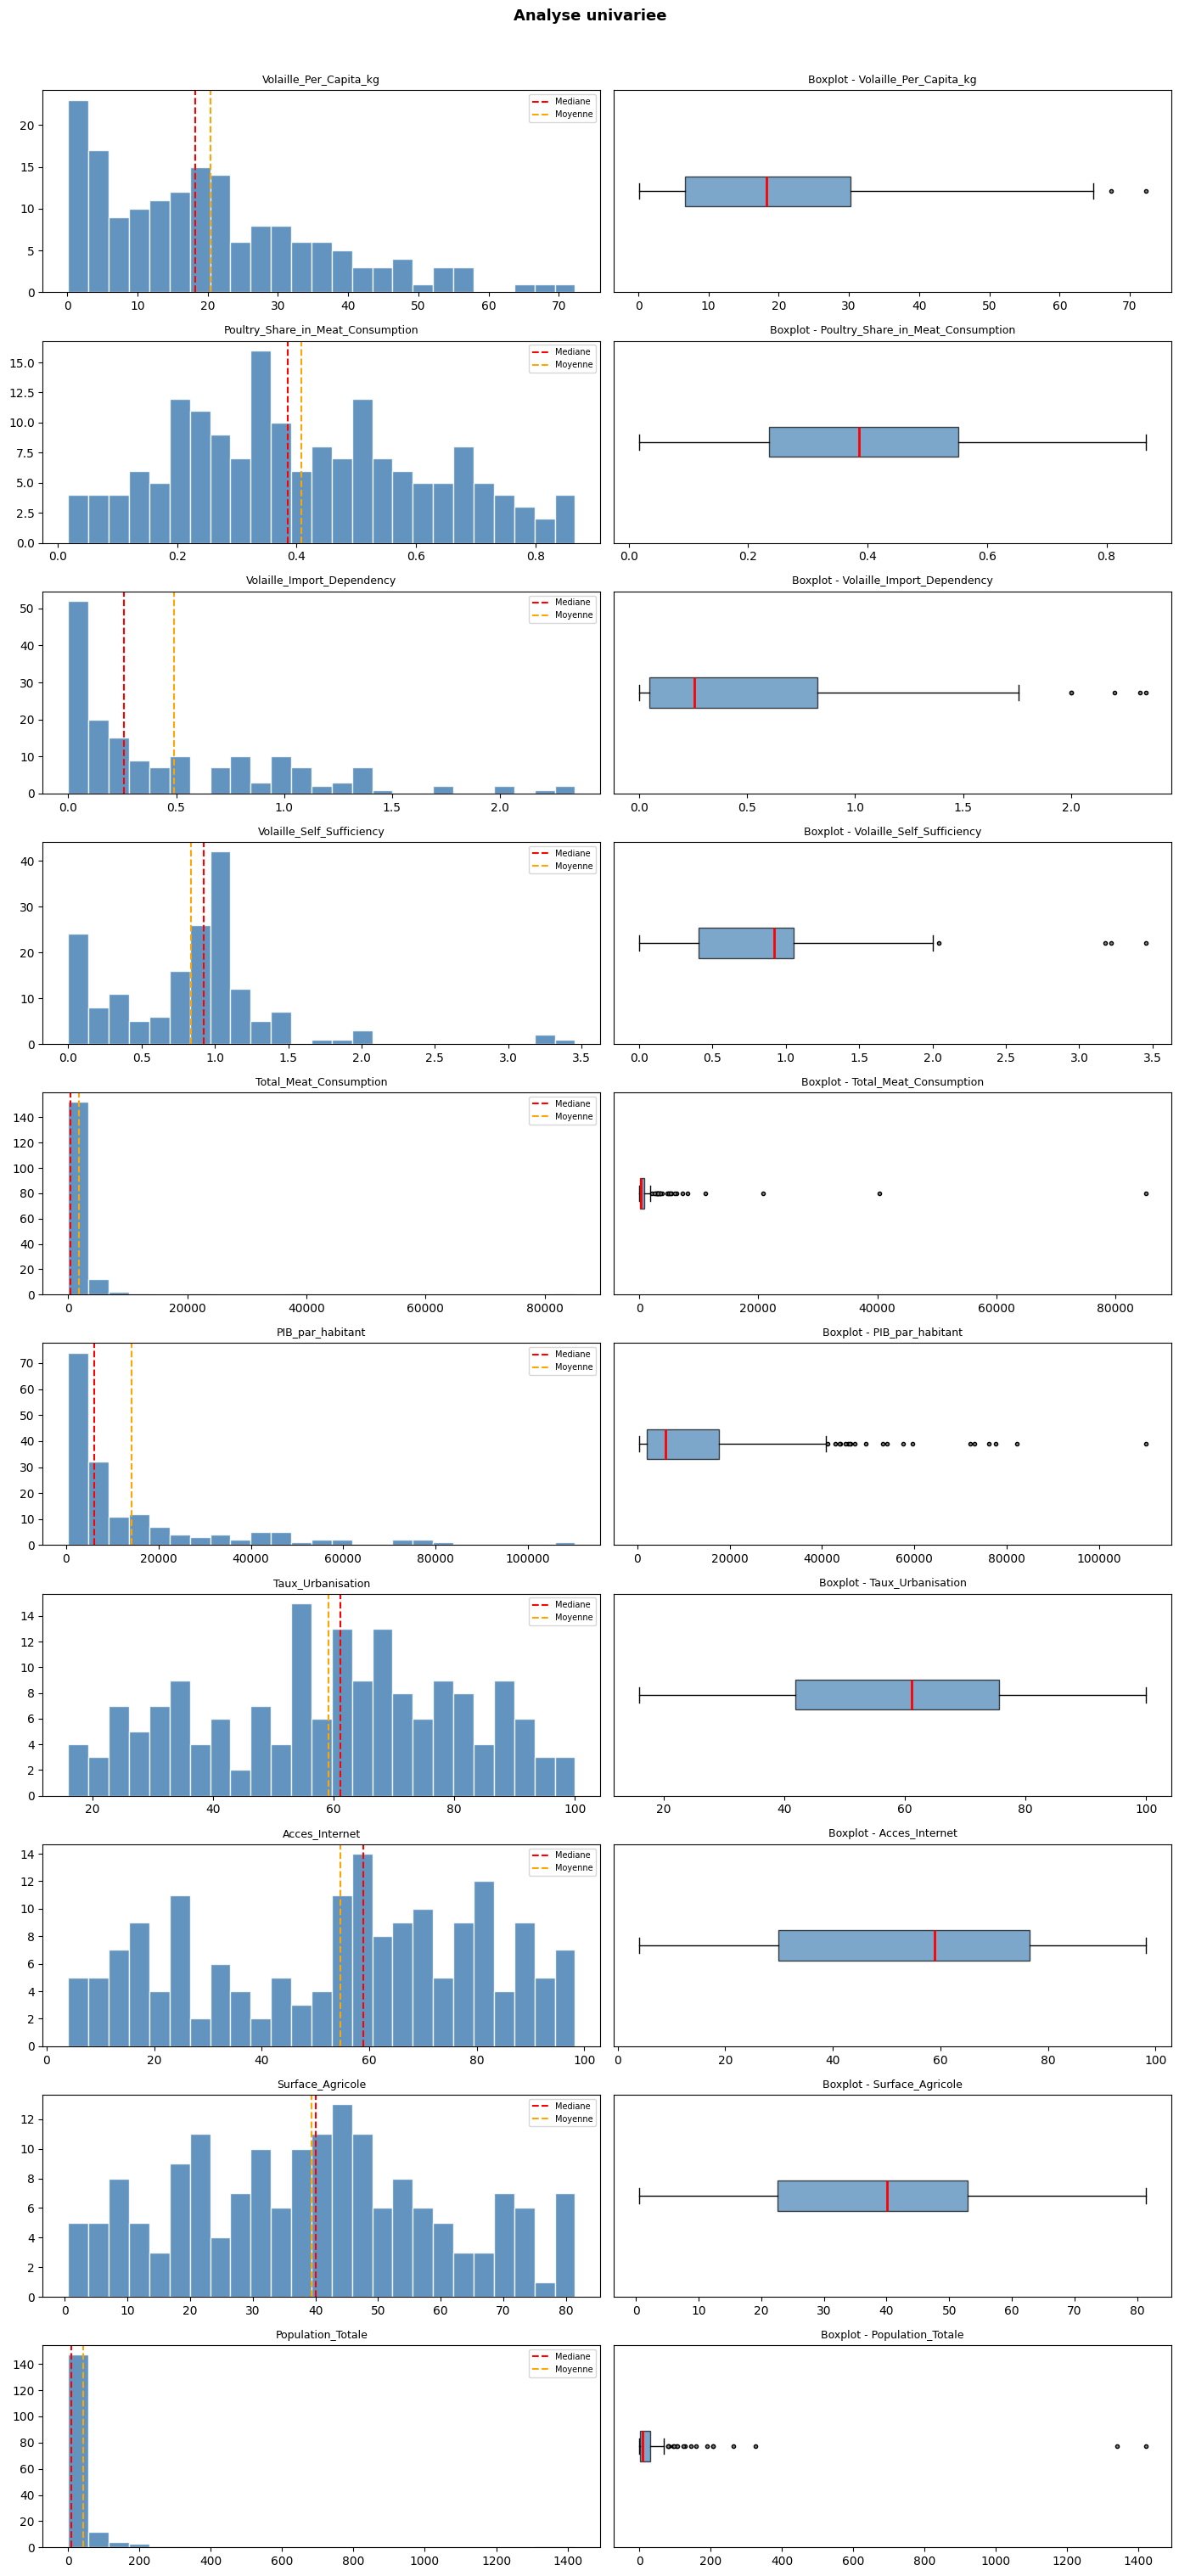

In [14]:
fig, axes = plt.subplots(len(vars_analyse), 2, figsize=(14, len(vars_analyse)*3))

for i, var in enumerate(vars_analyse):
    data = df[var].dropna()
    axes[i,0].hist(data, bins=25, color='steelblue', edgecolor='white', alpha=0.85)
    axes[i,0].axvline(data.median(), color='red', ls='--', lw=1.5, label='Mediane')
    axes[i,0].axvline(data.mean(), color='orange', ls='--', lw=1.5, label='Moyenne')
    axes[i,0].set_title(var, fontsize=9)
    axes[i,0].legend(fontsize=7)
    axes[i,1].boxplot(data, vert=False, patch_artist=True,
                      boxprops=dict(facecolor='steelblue', alpha=0.7),
                      medianprops=dict(color='red', linewidth=2),
                      flierprops=dict(marker='o', markerfacecolor='gray', markersize=3))
    axes[i,1].set_title(f'Boxplot - {var}', fontsize=9)
    axes[i,1].set_yticks([])

plt.suptitle('Analyse univariee', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('univariee.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.2 Analyse univariée - Histogrammes et boîtes à moustaches

Pour chaque variable :
- **Histogramme** (gauche) : distribution des valeurs avec médiane (rouge) et moyenne (orange)
- **Boîte à moustaches** (droite) : détection des outliers (points au-delà des moustaches)

**Interprétation clé :** si la moyenne est très supérieure à la médiane, la distribution est asymétrique à droite - quelques pays "géants" tirent la moyenne vers le haut (ex : Chine, USA pour la production).

### 7.3 Matrice de corrélations (analyse bivariée)

La heatmap mesure les corrélations entre toutes les variables candidates. Les corrélations fortes (|r| > 0,6) signalent des **redondances** à traiter avant l'ACP.


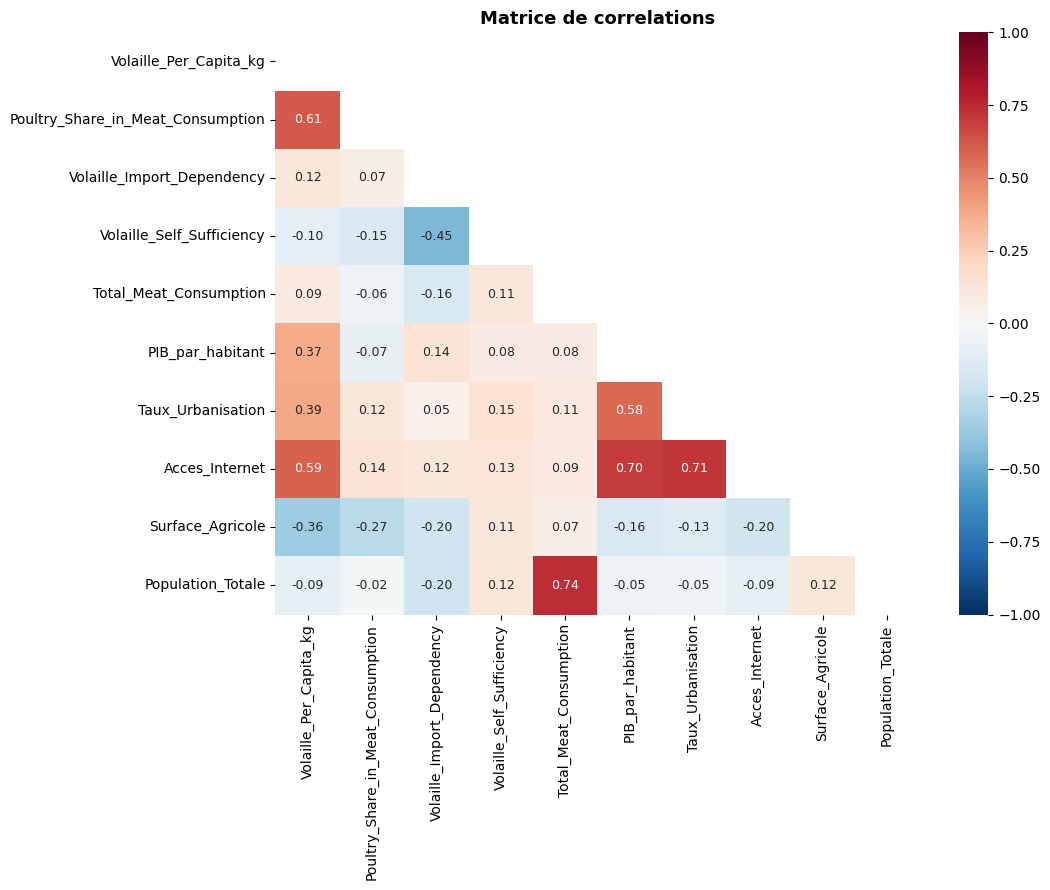

Correlations fortes (|r| > 0.6) :
  Volaille_Per_Capita_kg <-> Poultry_Share_in_Meat_Consumption : r=0.61
  Total_Meat_Consumption <-> Population_Totale : r=0.74
  PIB_par_habitant <-> Acces_Internet : r=0.70
  Taux_Urbanisation <-> Acces_Internet : r=0.71


In [15]:
corr = df[vars_analyse].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size':9})
ax.set_title('Matrice de correlations', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('correlations.png', dpi=120, bbox_inches='tight')
plt.show()

print('Correlations fortes (|r| > 0.6) :')
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        r = corr.iloc[i,j]
        if abs(r) > 0.6:
            print(f'  {corr.columns[i]} <-> {corr.columns[j]} : r={r:.2f}')

In [16]:
vars_finales = [
    'Zone', 'Code_ISO3',
    'Volaille_Per_Capita_kg',
    'Volaille_Import_Dependency',
    'Volaille_Net_Import',
    'Volaille_Production_Gap',
    'Poultry_Share_in_Meat_Consumption',
    'Viandes_Import_Dependency',
    'Volaille_Import_Cover_Ratio',
    'PIB_par_habitant',
    'Taux_Urbanisation',
    'Acces_Internet',
    'Surface_Agricole',
    'Population_Totale',
]

manquantes = [v for v in vars_finales if v not in df.columns]
if manquantes:
    print(f'ATTENTION variables manquantes dans df : {manquantes}')

df_save = df[[c for c in vars_finales if c in df.columns]].copy()
df_save.to_csv('dataset_poule_qui_chante.csv', index=False, encoding='utf-8-sig')
print(f'Sauvegarde : {df_save.shape[0]} pays x {df_save.shape[1]} variables')
df_save.head(3)

Sauvegarde : 170 pays x 14 variables


,Zone,Code_ISO3,Volaille_Per_Capita_kg,Volaille_Import_Dependency,Volaille_Net_Import,Volaille_Production_Gap,Poultry_Share_in_Meat_Consumption,Viandes_Import_Dependency,Volaille_Import_Cover_Ratio,PIB_par_habitant,Taux_Urbanisation,Acces_Internet,Surface_Agricole,Population_Totale
0,Afghanistan,AFG,1.53,0.5273,10.0,27.0,0.1763,0.0929,1.0741,525.469771,24.835282,13.500000,58.123668,36.30
1,Afrique du Sud,ZAF,35.69,0.2526,451.0,368.0,0.5947,0.1502,1.3967,6618.335083,63.331108,56.167400,79.417850,57.01
2,Albanie,ALB,16.36,0.8085,38.0,34.0,0.3456,0.2794,1.1176,5006.360130,55.980276,62.400002,42.856971,2.88
